
# Walmart Retail Performance & Risk Intelligence

### A 45-store operating system: revenue concentration, holiday response, volatility and macro sensitivity

This notebook treats the Walmart file as a connected retail network rather than 6,435 unrelated rows. The analysis moves through four lenses:

- **Portfolio:** which stores carry the sales base, and how concentrated is that base?
- **Calendar:** which holiday weeks create genuine uplift, and which are merely labelled as holidays?
- **Stability:** where is weekly revenue volatile relative to the store's own scale?
- **Exposure:** do macroeconomic movements explain store-level sales changes once calendar effects are considered?

The dataset contains one observation per store and week. The macroeconomic fields vary across stores and weeks. The correlation section therefore compares the pooled store-week view with a 143-week market-level view built from total sales and average store-level indicators.

> **Decision principle:** a store can be large but stable, small but volatile, or holiday-responsive while still declining on a like-for-like basis. Those are different management problems and should not be collapsed into one ranking.



## Analytical setup

The source file is the supplied Kaggle Walmart dataset. The analysis preserves the original store-week grain, adds a small set of calendar labels, and creates derived tables for ranking, holiday comparisons, annual pivots and unemployment sensitivity.

The requested Desktop location is used as the notebook's default input path. The included `data/Walmart.csv` is also supplied for a portable project copy; when running from another machine, only the `DATA_PATH` value needs to be changed if the Desktop path differs.


In [1]:

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.formula.api import ols
from statsmodels.stats.multitest import multipletests
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (12, 6),
    "figure.dpi": 120,
    "axes.titleweight": "bold",
    "axes.titlesize": 15,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.frameon": False,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

OUTPUT_DIR = Path("outputs")
VISUAL_DIR = Path("visuals")
OUTPUT_DIR.mkdir(exist_ok=True)
VISUAL_DIR.mkdir(exist_ok=True)

print("Libraries loaded. Output folders are ready.")


Libraries loaded. Output folders are ready.



## Load the source file

The source is read directly with `pandas.read_csv`. No file-discovery branch or `if/else` fallback is used in the loading step.


In [2]:

DATA_PATH = r"C:\Users\anarrasulzada\Desktop\Walmart.csv"

df = pd.read_csv(DATA_PATH)

print(f"Rows: {len(df):,} | Columns: {df.shape[1]}")
display(df.head())


Rows: 6,435 | Columns: 8


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106



## Data contract and quality checks

Dates are stored as day-month-year strings in the source. The data is sorted by store and date before any lag, difference or weekly volatility calculation. Each store should have the same 143 weekly observations; the validation below checks the actual file rather than assuming the expected structure.


In [3]:

df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")
df = df.sort_values(["Store", "Date"]).reset_index(drop=True)

df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Month_Start"] = df["Date"].dt.to_period("M").dt.to_timestamp()

quality = pd.Series({
    "rows": len(df),
    "stores": df["Store"].nunique(),
    "unique weekly dates": df["Date"].nunique(),
    "date range start": df["Date"].min().date(),
    "date range end": df["Date"].max().date(),
    "missing cells": int(df.isna().sum().sum()),
    "duplicate Store-Date keys": int(df.duplicated(["Store", "Date"]).sum()),
    "holiday rows": int(df["Holiday_Flag"].sum()),
    "weeks per store (minimum)": int(df.groupby("Store").size().min()),
    "weeks per store (maximum)": int(df.groupby("Store").size().max()),
})
display(quality.to_frame("Observed value"))

assert len(df) == 6435
assert df["Store"].nunique() == 45
assert df["Date"].nunique() == 143
assert df.isna().sum().sum() == 0
assert df.duplicated(["Store", "Date"]).sum() == 0
assert df.groupby("Store").size().eq(143).all()

year_coverage = (
    df.groupby("Year")
      .agg(first_week=("Date", "min"), last_week=("Date", "max"),
           observed_weeks=("Date", "nunique"))
)
display(year_coverage)


,Observed value
rows,6435
stores,45
unique weekly dates,143
date range start,2010-02-05
date range end,2012-10-26
missing cells,0
duplicate Store-Date keys,0
holiday rows,450
weeks per store (minimum),143
weeks per store (maximum),143


,first_week,last_week,observed_weeks
Year,,,
2010,2010-02-05,2010-12-31,48
2011,2011-01-07,2011-12-30,52
2012,2012-01-06,2012-10-26,43



## Build the holiday calendar

The holiday flag identifies the week associated with a major retail event. The calendar below labels the known Super Bowl, Labour Day, Thanksgiving and Christmas dates. The source ends on 26 October 2012, so the 2012 Thanksgiving and Christmas dates are outside the observed window and are not treated as observed events.


In [4]:

HOLIDAY_DATES = {
    "2010-02-12": "Super Bowl",
    "2011-02-11": "Super Bowl",
    "2012-02-10": "Super Bowl",
    "2010-09-10": "Labour Day",
    "2011-09-09": "Labour Day",
    "2012-09-07": "Labour Day",
    "2010-11-26": "Thanksgiving",
    "2011-11-25": "Thanksgiving",
    "2012-11-23": "Thanksgiving",
    "2010-12-31": "Christmas",
    "2011-12-30": "Christmas",
    "2012-12-28": "Christmas",
}

df["Holiday_Type"] = (
    df["Date"].dt.strftime("%Y-%m-%d").map(HOLIDAY_DATES).fillna("Non-holiday")
)

observed_holiday_dates = (
    df.loc[df["Holiday_Flag"].eq(1), ["Date", "Holiday_Type"]]
      .drop_duplicates()
      .sort_values("Date")
      .reset_index(drop=True)
)

assert observed_holiday_dates["Holiday_Type"].ne("Non-holiday").all()
assert observed_holiday_dates["Date"].nunique() == 10
assert df.loc[df["Holiday_Flag"].eq(1), "Holiday_Type"].ne("Non-holiday").all()

display(observed_holiday_dates)
print(f"Observed event dates: {len(observed_holiday_dates)}")
print(f"Holiday store-week rows: {int(df['Holiday_Flag'].sum()):,}")


,Date,Holiday_Type
0,2010-02-12,Super Bowl
1,2010-09-10,Labour Day
2,2010-11-26,Thanksgiving
3,2010-12-31,Christmas
4,2011-02-11,Super Bowl
5,2011-09-09,Labour Day
6,2011-11-25,Thanksgiving
7,2011-12-30,Christmas
8,2012-02-10,Super Bowl
9,2012-09-07,Labour Day


Observed event dates: 10
Holiday store-week rows: 450



## Store portfolio: scale, rank and tier

The ranking uses cumulative sales across the observed window. Tiers are fixed by rank rather than by arbitrary revenue thresholds: the first 10 stores form the Top tier, the next 25 form Mid, and the final 10 form Bottom. This makes the segmentation exhaustive and easy to reproduce.


In [5]:

store_performance = (
    df.groupby("Store")["Weekly_Sales"]
      .agg(total_sales="sum",
           avg_weekly_sales="mean",
           median_weekly_sales="median",
           std_weekly_sales="std",
           min_weekly_sales="min",
           max_weekly_sales="max")
)

store_performance["cv_pct"] = (
    store_performance["std_weekly_sales"] /
    store_performance["avg_weekly_sales"] * 100
)
store_performance["rank"] = (
    store_performance["total_sales"]
    .rank(method="first", ascending=False)
    .astype(int)
)
store_performance["tier"] = np.select(
    [
        store_performance["rank"].le(10),
        store_performance["rank"].between(11, 35),
    ],
    ["Top 10", "Mid 25"],
    default="Bottom 10",
)

store_performance = store_performance.sort_values("rank")
store_performance["total_sales_m"] = store_performance["total_sales"] / 1_000_000
store_performance["avg_weekly_sales_m"] = store_performance["avg_weekly_sales"] / 1_000_000

tier_summary = (
    store_performance.groupby("tier", sort=False)
    .agg(stores=("rank", "count"),
         total_sales=("total_sales", "sum"),
         average_store_sales=("total_sales", "mean"))
)
tier_summary["sales_share_pct"] = tier_summary["total_sales"] / df["Weekly_Sales"].sum() * 100

display(store_performance[[
    "rank", "tier", "total_sales", "avg_weekly_sales",
    "std_weekly_sales", "cv_pct"
]].head(12).style.format({
    "total_sales": "${:,.0f}",
    "avg_weekly_sales": "${:,.0f}",
    "std_weekly_sales": "${:,.0f}",
    "cv_pct": "{:.2f}%"
}))
display(tier_summary.style.format({
    "total_sales": "${:,.0f}",
    "average_store_sales": "${:,.0f}",
    "sales_share_pct": "{:.2f}%"
}))

top_store = int(store_performance.index[0])
bottom_store = int(store_performance.index[-1])
print(
    f"Sales leader: Store {top_store} (${store_performance.loc[top_store, 'total_sales']/1e6:.1f}M). "
    f"Lowest cumulative sales: Store {bottom_store} "
    f"(${store_performance.loc[bottom_store, 'total_sales']/1e6:.1f}M)."
)


,rank,tier,total_sales,avg_weekly_sales,std_weekly_sales,cv_pct
Store,,,,,,
20,1,Top 10,"$301,397,792","$2,107,677","$275,901",13.09%
4,2,Top 10,"$299,543,953","$2,094,713","$266,201",12.71%
14,3,Top 10,"$288,999,911","$2,020,978","$317,570",15.71%
13,4,Top 10,"$286,517,704","$2,003,620","$265,507",13.25%
2,5,Top 10,"$275,382,441","$1,925,751","$237,684",12.34%
10,6,Top 10,"$271,617,714","$1,899,425","$302,262",15.91%
27,7,Top 10,"$253,855,917","$1,775,216","$239,930",13.52%
6,8,Top 10,"$223,756,131","$1,564,728","$212,526",13.58%
1,9,Top 10,"$222,402,809","$1,555,264","$155,981",10.03%


,stores,total_sales,average_store_sales,sales_share_pct
tier,,,,
Top 10,10,"$2,630,919,915","$263,091,991",39.05%
Mid 25,25,"$3,525,897,892","$141,035,916",52.33%
Bottom 10,10,"$580,401,180","$58,040,118",8.61%


Sales leader: Store 20 ($301.4M). Lowest cumulative sales: Store 33 ($37.2M).



## Holiday economics: event uplift, not just a holiday label

Two comparisons are kept separate:

- **Raw holiday mean:** average sales per store-week where `Holiday_Flag = 1`, compared with non-holiday store-weeks.
- **Store-normalized event uplift:** each store's holiday-week sales are compared with that same store's average non-holiday sales. Store-level event averages are then averaged across the 45 stores.

The second measure is the primary event ranking because a large store should not dominate the result simply because its revenue base is larger.


In [6]:

normal_mean = df.loc[df["Holiday_Flag"].eq(0), "Weekly_Sales"].mean()
holiday_mean = df.loc[df["Holiday_Flag"].eq(1), "Weekly_Sales"].mean()
overall_holiday_uplift_pct = (holiday_mean / normal_mean - 1) * 100

normal_by_store = (
    df.loc[df["Holiday_Flag"].eq(0)]
      .groupby("Store")["Weekly_Sales"].mean()
)

holiday_rows = df.loc[df["Holiday_Flag"].eq(1)].copy()
holiday_rows["store_normal_mean"] = holiday_rows["Store"].map(normal_by_store)

event_store_means = (
    holiday_rows.groupby(["Store", "Holiday_Type"])["Weekly_Sales"]
    .mean()
    .rename("holiday_mean")
    .reset_index()
)
event_store_means["normal_mean"] = event_store_means["Store"].map(normal_by_store)
event_store_means["uplift_pct"] = (
    event_store_means["holiday_mean"] / event_store_means["normal_mean"] - 1
) * 100

holiday_ci_rows = []
for event, group in event_store_means.groupby("Holiday_Type"):
    values = group["uplift_pct"]
    n = len(values)
    mean_value = values.mean()
    standard_error = stats.sem(values)
    lower, upper = stats.t.interval(
        0.95, n - 1, loc=mean_value, scale=standard_error
    )
    holiday_ci_rows.append({
        "Holiday_Type": event,
        "stores": n,
        "mean_store_adjusted_uplift_pct": mean_value,
        "ci_lower_pct": lower,
        "ci_upper_pct": upper,
        "median_store_uplift_pct": values.median(),
    })

holiday_uplift_summary = pd.DataFrame(holiday_ci_rows).set_index("Holiday_Type")
holiday_uplift_summary = holiday_uplift_summary.sort_values(
    "mean_store_adjusted_uplift_pct", ascending=False
)

holiday_raw_summary = (
    holiday_rows.groupby("Holiday_Type")["Weekly_Sales"]
    .agg(mean_sales="mean", median_sales="median", store_week_rows="size")
)
holiday_raw_summary["uplift_vs_nonholiday_pct"] = (
    holiday_raw_summary["mean_sales"] / normal_mean - 1
) * 100
holiday_uplift_summary = holiday_uplift_summary.join(holiday_raw_summary)

overall_store_adjusted_uplift = (
    holiday_rows.assign(uplift_pct=(holiday_rows["Weekly_Sales"] / holiday_rows["store_normal_mean"] - 1) * 100)
    .groupby("Store")["uplift_pct"].mean().mean()
)

display(pd.DataFrame({
    "Average weekly sales": [normal_mean, holiday_mean],
    "Difference vs normal": [0, holiday_mean - normal_mean],
    "Uplift vs normal (%)": [0, overall_holiday_uplift_pct],
}, index=["Non-holiday", "Holiday"]).style.format({
    "Average weekly sales": "${:,.0f}",
    "Difference vs normal": "${:,.0f}",
    "Uplift vs normal (%)": "{:.2f}%"
}))

display(holiday_uplift_summary[[
    "stores", "mean_sales", "uplift_vs_nonholiday_pct",
    "mean_store_adjusted_uplift_pct", "ci_lower_pct", "ci_upper_pct"
]].style.format({
    "mean_sales": "${:,.0f}",
    "uplift_vs_nonholiday_pct": "{:+.2f}%",
    "mean_store_adjusted_uplift_pct": "{:+.2f}%",
    "ci_lower_pct": "{:+.2f}%",
    "ci_upper_pct": "{:+.2f}%"
}))

holiday_date_sales = (
    df.loc[df["Holiday_Flag"].eq(1)]
      .groupby(["Date", "Holiday_Type"])["Weekly_Sales"]
      .agg(total_store_sales="sum", average_store_sales="mean")
      .reset_index()
      .sort_values("Date")
)
display(holiday_date_sales.style.format({
    "total_store_sales": "${:,.0f}",
    "average_store_sales": "${:,.0f}"
}))

best_holiday = holiday_uplift_summary.index[0]
print(
    f"Highest store-normalized uplift: {best_holiday} "
    f"({holiday_uplift_summary.iloc[0]['mean_store_adjusted_uplift_pct']:+.1f}%)."
)
print(
    f"All holiday weeks combined: {overall_holiday_uplift_pct:+.2f}% raw uplift; "
    f"{overall_store_adjusted_uplift:+.2f}% store-normalized uplift."
)


,Average weekly sales,Difference vs normal,Uplift vs normal (%)
Non-holiday,"$1,041,256",$0,0.00%
Holiday,"$1,122,888","$81,632",7.84%


,stores,mean_sales,uplift_vs_nonholiday_pct,mean_store_adjusted_uplift_pct,ci_lower_pct,ci_upper_pct
Holiday_Type,,,,,,
Thanksgiving,45,"$1,471,273",+41.30%,+38.40%,+31.62%,+45.18%
Super Bowl,45,"$1,079,128",+3.64%,+3.42%,+1.34%,+5.51%
Labour Day,45,"$1,042,427",+0.11%,+0.56%,-1.75%,+2.87%
Christmas,45,"$960,833",-7.72%,-7.39%,-10.34%,-4.44%


,Date,Holiday_Type,total_store_sales,average_store_sales
0,2010-02-12 00:00:00,Super Bowl,"$48,336,678","$1,074,148"
1,2010-09-10 00:00:00,Labour Day,"$45,634,398","$1,014,098"
2,2010-11-26 00:00:00,Thanksgiving,"$65,821,003","$1,462,689"
3,2010-12-31 00:00:00,Christmas,"$40,432,519","$898,500"
4,2011-02-11 00:00:00,Super Bowl,"$47,336,193","$1,051,915"
5,2011-09-09 00:00:00,Labour Day,"$46,763,228","$1,039,183"
6,2011-11-25 00:00:00,Thanksgiving,"$66,593,605","$1,479,858"
7,2011-12-30 00:00:00,Christmas,"$46,042,461","$1,023,166"
8,2012-02-10 00:00:00,Super Bowl,"$50,009,408","$1,111,320"
9,2012-09-07 00:00:00,Labour Day,"$48,330,059","$1,074,001"


Highest store-normalized uplift: Thanksgiving (+38.4%).
All holiday weeks combined: +7.84% raw uplift; +7.40% store-normalized uplift.



## Monthly sales rhythm

Monthly totals are built by summing all store-week sales within each calendar month. The number of weekly observations is retained because months contain different numbers of Friday-ending weeks and the dataset begins and ends part-way through a year.


In [7]:

monthly_trend = (
    df.groupby("Month_Start")
      .agg(monthly_sales=("Weekly_Sales", "sum"),
           observed_week_dates=("Date", "nunique"))
      .reset_index()
)
monthly_trend["monthly_sales_m"] = monthly_trend["monthly_sales"] / 1_000_000
monthly_trend["Year"] = monthly_trend["Month_Start"].dt.year
monthly_trend["Month_Label"] = monthly_trend["Month_Start"].dt.strftime("%b %Y")

peak_month = monthly_trend.loc[monthly_trend["monthly_sales"].idxmax()]
weekly_totals = (
    df.groupby("Date")["Weekly_Sales"].sum().rename("network_sales").reset_index()
)
peak_week = weekly_totals.loc[weekly_totals["network_sales"].idxmax()]

display(monthly_trend.sort_values("monthly_sales", ascending=False).head(8).style.format({
    "monthly_sales": "${:,.0f}",
    "monthly_sales_m": "${:.1f}M"
}))
print(
    f"Highest monthly total: {peak_month['Month_Label']} "
    f"(${peak_month['monthly_sales_m']:.1f}M)."
)
print(
    f"Highest single week: {peak_week['Date'].date()} "
    f"(${peak_week['network_sales']/1e6:.1f}M across all stores)."
)


,Month_Start,monthly_sales,observed_week_dates,monthly_sales_m,Year,Month_Label
10,2010-12-01 00:00:00,"$288,760,533",5,$288.8M,2010,Dec 2010
22,2011-12-01 00:00:00,"$288,078,102",5,$288.1M,2011,Dec 2011
28,2012-06-01 00:00:00,"$240,610,329",5,$240.6M,2012,Jun 2012
30,2012-08-01 00:00:00,"$236,850,766",5,$236.9M,2012,Aug 2012
5,2010-07-01 00:00:00,"$232,580,126",5,$232.6M,2010,Jul 2010
25,2012-03-01 00:00:00,"$231,509,650",5,$231.5M,2012,Mar 2012
2,2010-04-01 00:00:00,"$231,412,368",5,$231.4M,2010,Apr 2010
17,2011-07-01 00:00:00,"$229,911,399",5,$229.9M,2011,Jul 2011


Highest monthly total: Dec 2010 ($288.8M).
Highest single week: 2010-12-24 ($80.9M across all stores).



## Store × Year: annual totals and the partial-year trap

The requested pivot is presented in raw dollars with YoY growth. However, the observation window is not three complete calendar years: 2010 begins in February and 2012 ends in October. Raw 2012-vs-2011 growth therefore understates performance because it compares 43 observed weeks with 52.

A second view uses the same February–October window in all three years. Each year contributes exactly 39 weekly dates, allowing a like-for-like comparison without pretending that partial annual totals are full-year results.


In [8]:

store_year_pivot = (
    df.pivot_table(index="Store", columns="Year", values="Weekly_Sales", aggfunc="sum")
    .sort_index()
)
store_year_yoy = store_year_pivot.pct_change(axis=1) * 100

display(store_year_pivot.head(10).style.format("${:,.0f}"))
display(store_year_yoy.head(10).style.format("{:+.2f}%"))

like_for_like = (
    df.loc[df["Month"].between(2, 10)]
      .groupby(["Store", "Year"])["Weekly_Sales"]
      .sum()
      .unstack("Year")
)
like_for_like_weeks = (
    df.loc[df["Month"].between(2, 10)]
      .groupby("Year")["Date"].nunique()
)
assert like_for_like_weeks.eq(39).all()

like_for_like_growth = pd.DataFrame(index=like_for_like.index)
like_for_like_growth["2011_vs_2010_pct"] = (
    like_for_like[2011] / like_for_like[2010] - 1
) * 100
like_for_like_growth["2012_vs_2011_pct"] = (
    like_for_like[2012] / like_for_like[2011] - 1
) * 100

print("Comparable February–October observation counts:")
display(like_for_like_weeks.to_frame("weekly dates"))
print("Store-level 2012 vs 2011 like-for-like growth:")
display(like_for_like_growth.sort_values("2012_vs_2011_pct").head(10).style.format("{:+.2f}%"))
print(
    f"Median raw annual YoY: 2011 vs 2010 = {store_year_yoy[2011].median():+.2f}%; "
    f"2012 vs 2011 = {store_year_yoy[2012].median():+.2f}% (partial-year comparison)."
)
print(
    f"Median like-for-like growth: 2011 vs 2010 = "
    f"{like_for_like_growth['2011_vs_2010_pct'].median():+.2f}%; "
    f"2012 vs 2011 = {like_for_like_growth['2012_vs_2011_pct'].median():+.2f}%."
)


Year,2010,2011,2012
Store,,,
1,"$73,278,832","$80,921,919","$68,202,058"
2,"$95,277,864","$98,607,881","$81,496,695"
3,"$18,745,419","$20,816,877","$18,024,440"
4,"$95,680,471","$111,092,293","$92,771,189"
5,"$14,836,031","$16,470,820","$14,168,838"
6,"$76,912,321","$80,528,763","$66,315,047"
7,"$25,568,078","$30,662,641","$25,367,556"
8,"$43,204,475","$47,512,786","$39,233,920"
9,"$25,129,220","$28,685,970","$23,974,030"


Year,2010,2011,2012
Store,,,
1,+nan%,+10.43%,-15.72%
2,+nan%,+3.50%,-17.35%
3,+nan%,+11.05%,-13.41%
4,+nan%,+16.11%,-16.49%
5,+nan%,+11.02%,-13.98%
6,+nan%,+4.70%,-17.65%
7,+nan%,+19.93%,-17.27%
8,+nan%,+9.97%,-17.42%
9,+nan%,+14.15%,-16.43%


Comparable February–October observation counts:


,weekly dates
Year,
2010,39
2011,39
2012,39


Store-level 2012 vs 2011 like-for-like growth:


,2011_vs_2010_pct,2012_vs_2011_pct
Store,,
36,-17.13%,-17.47%
14,-6.68%,-9.35%
21,+0.90%,-5.25%
27,-4.85%,-2.55%
15,-5.12%,-1.75%
28,-0.78%,-1.01%
19,-4.16%,-0.71%
31,+5.49%,-0.45%
10,-2.88%,+0.99%


Median raw annual YoY: 2011 vs 2010 = +7.97%; 2012 vs 2011 = -17.50% (partial-year comparison).
Median like-for-like growth: 2011 vs 2010 = +0.89%; 2012 vs 2011 = +3.46%.



## Volatility: absolute dollars versus relative instability

Standard deviation answers how many dollars weekly sales typically move around. The coefficient of variation (CV) divides that standard deviation by the store's average weekly sales, making it more useful when comparing a large store with a small one. Both rankings are retained because they answer different operational questions.


In [9]:

volatility_view = store_performance[[
    "avg_weekly_sales", "std_weekly_sales", "cv_pct", "rank", "tier"
]].copy()

highest_absolute_volatility = volatility_view.sort_values(
    "std_weekly_sales", ascending=False
).head(10)
highest_relative_volatility = volatility_view.sort_values(
    "cv_pct", ascending=False
).head(10)

print("Highest absolute weekly sales standard deviation:")
display(highest_absolute_volatility.style.format({
    "avg_weekly_sales": "${:,.0f}",
    "std_weekly_sales": "${:,.0f}",
    "cv_pct": "{:.2f}%"
}))
print("Highest relative volatility (coefficient of variation):")
display(highest_relative_volatility.style.format({
    "avg_weekly_sales": "${:,.0f}",
    "std_weekly_sales": "${:,.0f}",
    "cv_pct": "{:.2f}%"
}))


Highest absolute weekly sales standard deviation:


,avg_weekly_sales,std_weekly_sales,cv_pct,rank,tier
Store,,,,,
14,"$2,020,978","$317,570",15.71%,3,Top 10
10,"$1,899,425","$302,262",15.91%,6,Top 10
20,"$2,107,677","$275,901",13.09%,1,Top 10
4,"$2,094,713","$266,201",12.71%,2,Top 10
13,"$2,003,620","$265,507",13.25%,4,Top 10
23,"$1,389,864","$249,788",17.97%,13,Mid 25
27,"$1,775,216","$239,930",13.52%,7,Top 10
2,"$1,925,751","$237,684",12.34%,5,Top 10
39,"$1,450,668","$217,466",14.99%,10,Top 10


Highest relative volatility (coefficient of variation):


,avg_weekly_sales,std_weekly_sales,cv_pct,rank,tier
Store,,,,,
35,"$919,725","$211,243",22.97%,25,Mid 25
7,"$570,617","$112,585",19.73%,33,Mid 25
15,"$623,312","$120,539",19.34%,32,Mid 25
29,"$539,451","$99,120",18.37%,36,Bottom 10
23,"$1,389,864","$249,788",17.97%,13,Mid 25
21,"$756,069","$128,753",17.03%,29,Mid 25
45,"$785,981","$130,169",16.56%,28,Mid 25
16,"$519,248","$85,770",16.52%,37,Bottom 10
18,"$1,084,718","$176,642",16.28%,19,Mid 25



## External factors: use the week as the observation unit

Temperature, fuel price, CPI and unemployment vary across stores as well as across weeks. The pooled store-week correlation preserves that local variation, but the 6,435 records are clustered across 45 stores and 143 common dates; its p-values should not be read as if every row were independent.

The market-level series below sums sales across all stores and averages the store-level economic indicators into one observation per date (143 weeks). This trades away local variation to provide a clean network-wide view.


In [10]:

macro_variables = ["Temperature", "Fuel_Price", "CPI", "Unemployment"]

macro_dispersion = df.groupby("Date")[macro_variables].nunique().mean().rename("mean distinct store values per week")
display(macro_dispersion.to_frame())

weekly_macro = (
    df.groupby("Date")
      .agg(Weekly_Sales=("Weekly_Sales", "sum"),
           Temperature=("Temperature", "mean"),
           Fuel_Price=("Fuel_Price", "mean"),
           CPI=("CPI", "mean"),
           Unemployment=("Unemployment", "mean"),
           Holiday_Flag=("Holiday_Flag", "max"))
      .sort_index()
      .reset_index()
)

correlation_rows = []
for variable in macro_variables:
    row_r, row_p = stats.pearsonr(df[variable], df["Weekly_Sales"])
    week_r, week_p = stats.pearsonr(weekly_macro[variable], weekly_macro["Weekly_Sales"])
    week_spearman, week_spearman_p = stats.spearmanr(
        weekly_macro[variable], weekly_macro["Weekly_Sales"]
    )
    correlation_rows.append({
        "Indicator": variable,
        "Store-week Pearson r": row_r,
        "Weekly aggregate Pearson r": week_r,
        "Weekly aggregate p-value": week_p,
        "Weekly aggregate Spearman r": week_spearman,
        "Weekly aggregate Spearman p-value": week_spearman_p,
    })

macro_correlations = pd.DataFrame(correlation_rows).set_index("Indicator")
macro_predictor_correlation = weekly_macro[macro_variables].corr()

display(macro_correlations.style.format({
    "Store-week Pearson r": "{:+.3f}",
    "Weekly aggregate Pearson r": "{:+.3f}",
    "Weekly aggregate p-value": "{:.3f}",
    "Weekly aggregate Spearman r": "{:+.3f}",
    "Weekly aggregate Spearman p-value": "{:.3f}"
}))
print("Correlation among the macroeconomic predictors:")
display(macro_predictor_correlation.style.format("{:+.2f}"))


,mean distinct store values per week
Temperature,34.804196
Fuel_Price,9.321678
CPI,15.000000
Unemployment,29.734266


,Store-week Pearson r,Weekly aggregate Pearson r,Weekly aggregate p-value,Weekly aggregate Spearman r,Weekly aggregate Spearman p-value
Indicator,,,,,
Temperature,-0.064,-0.159,0.058,+0.056,0.505
Fuel_Price,+0.009,-0.057,0.501,-0.001,0.991
CPI,-0.073,+0.023,0.781,+0.063,0.451
Unemployment,-0.106,+0.004,0.967,-0.065,0.443


Correlation among the macroeconomic predictors:


,Temperature,Fuel_Price,CPI,Unemployment
Temperature,+1.00,+0.21,+0.16,-0.17
Fuel_Price,+0.21,+1.00,+0.82,-0.75
CPI,+0.16,+0.82,+1.00,-0.98
Unemployment,-0.17,-0.75,-0.98,+1.00



## Unemployment sensitivity: two specifications, one consistent signal

A store's raw sales–unemployment correlation can mostly reflect store size, seasonality or a shared time trend. The primary model therefore uses weekly changes in log sales and weekly changes in the macro indicators, with month-of-year controls and Newey–West (HAC) standard errors. The coefficient estimates the association between a one-percentage-point change in unemployment and the store's weekly sales growth, conditional on the other included changes and month effects.

A second level model adds a time trend and the macro indicator levels. It is used as a robustness check, not as a causal model. CPI, fuel price, unemployment and time are strongly collinear in this short historical sample.


In [11]:

sensitivity_rows = []
level_sensitivity_rows = []

for store, group in df.groupby("Store"):
    g = group.sort_values("Date").copy()
    g["d_log_sales"] = np.log(g["Weekly_Sales"]).diff()
    g["d_unemployment"] = g["Unemployment"].diff()
    g["d_temperature"] = g["Temperature"].diff()
    g["d_fuel_price"] = g["Fuel_Price"].diff()
    g["d_cpi"] = g["CPI"].diff()
    g["Month_Control"] = g["Date"].dt.month

    change_model = ols(
        "d_log_sales ~ d_unemployment + d_temperature + d_fuel_price + d_cpi + C(Month_Control)",
        data=g.dropna()
    ).fit(cov_type="HAC", cov_kwds={"maxlags": 4})

    beta = change_model.params["d_unemployment"]
    ci_low, ci_high = change_model.conf_int().loc["d_unemployment"]

    sensitivity_rows.append({
        "Store": store,
        "beta_unemployment_change": beta,
        "ci_lower": ci_low,
        "ci_upper": ci_high,
        "p_value": change_model.pvalues["d_unemployment"],
        "r_squared": change_model.rsquared,
        "observations": int(change_model.nobs),
    })

    level = group.sort_values("Date").copy()
    level["log_weekly_sales"] = np.log(level["Weekly_Sales"])
    level["time_trend"] = np.arange(len(level))
    level["Month_Control"] = level["Date"].dt.month

    level_model = ols(
        "log_weekly_sales ~ Unemployment + Temperature + Fuel_Price + CPI + time_trend + C(Month_Control)",
        data=level
    ).fit(cov_type="HAC", cov_kwds={"maxlags": 4})

    level_sensitivity_rows.append({
        "Store": store,
        "level_beta_unemployment": level_model.params["Unemployment"],
        "level_p_value": level_model.pvalues["Unemployment"],
        "level_r_squared": level_model.rsquared,
    })

unemployment_sensitivity = pd.DataFrame(sensitivity_rows).set_index("Store")
unemployment_sensitivity["p_fdr"] = multipletests(
    unemployment_sensitivity["p_value"], method="fdr_bh"
)[1]
unemployment_sensitivity["fdr_significant"] = unemployment_sensitivity["p_fdr"].lt(0.05)
unemployment_sensitivity["implied_change_for_0_1pp_pct"] = (
    np.exp(unemployment_sensitivity["beta_unemployment_change"] * 0.1) - 1
) * 100
unemployment_sensitivity = unemployment_sensitivity.sort_values(
    "beta_unemployment_change"
)

level_sensitivity = pd.DataFrame(level_sensitivity_rows).set_index("Store")
level_sensitivity["level_p_fdr"] = multipletests(
    level_sensitivity["level_p_value"], method="fdr_bh"
)[1]

sensitivity_robustness = unemployment_sensitivity.join(level_sensitivity)
nonzero_unemployment_changes = int(
    weekly_macro["Unemployment"].diff().fillna(0).ne(0).sum()
)

display(unemployment_sensitivity.head(10).style.format({
    "beta_unemployment_change": "{:+.3f}",
    "ci_lower": "{:+.3f}",
    "ci_upper": "{:+.3f}",
    "p_value": "{:.4f}",
    "p_fdr": "{:.4f}",
    "r_squared": "{:.3f}",
    "implied_change_for_0_1pp_pct": "{:+.2f}%"
}))
print(f"Non-zero week-to-week unemployment changes: {nonzero_unemployment_changes} of 142 transitions.")
print("Cross-specification leaders:")
display(
    sensitivity_robustness.loc[[42, 26, 40, 28, 33, 18, 14], [
        "beta_unemployment_change", "p_fdr",
        "level_beta_unemployment", "level_p_fdr"
    ]].style.format({
        "beta_unemployment_change": "{:+.3f}",
        "p_fdr": "{:.4f}",
        "level_beta_unemployment": "{:+.3f}",
        "level_p_fdr": "{:.4f}"
    })
)


,beta_unemployment_change,ci_lower,ci_upper,p_value,r_squared,observations,p_fdr,fdr_significant,implied_change_for_0_1pp_pct
Store,,,,,,,,,
42,-0.689,-0.989,-0.389,0.0000,0.190,142,0.0001,True,-6.66%
26,-0.524,-0.774,-0.274,0.0000,0.105,142,0.0003,True,-5.11%
40,-0.521,-0.809,-0.232,0.0004,0.098,142,0.0018,True,-5.07%
28,-0.425,-0.533,-0.317,0.0000,0.156,142,0.0000,True,-4.16%
41,-0.387,-0.636,-0.139,0.0022,0.124,142,0.0067,True,-3.80%
23,-0.386,-0.618,-0.155,0.0011,0.166,142,0.0037,True,-3.79%
8,-0.350,-0.550,-0.150,0.0006,0.137,142,0.0024,True,-3.44%
38,-0.341,-0.449,-0.234,0.0000,0.245,142,0.0000,True,-3.36%
17,-0.324,-0.830,+0.183,0.2100,0.071,142,0.3259,False,-3.19%


Non-zero week-to-week unemployment changes: 11 of 142 transitions.
Cross-specification leaders:


,beta_unemployment_change,p_fdr,level_beta_unemployment,level_p_fdr
Store,,,,
42,-0.689,0.0001,-0.707,0.0000
26,-0.524,0.0003,-0.217,0.5353
40,-0.521,0.0018,-0.049,0.5602
28,-0.425,0.0000,-0.027,0.3069
33,-0.310,0.0016,-0.379,0.0035
18,-0.056,0.8382,-0.322,0.0008
14,-0.086,0.8779,-0.298,0.0001



## Investigation queue: falling comparable sales despite positive holiday response

The 2012 annual total is incomplete, so the investigation flag uses a consistent February–October window. A store is flagged when its 2012 sales are below its 2011 sales over the same 39 weekly dates **and** its 2012 Super Bowl/Labour Day weeks average above its own non-holiday baseline in that window.


In [12]:

window_2012 = df.loc[
    df["Year"].eq(2012) & df["Month"].between(2, 10)
].copy()

holiday_2012_mean = (
    window_2012.loc[window_2012["Holiday_Flag"].eq(1)]
    .groupby("Store")["Weekly_Sales"].mean()
)
normal_2012_mean = (
    window_2012.loc[window_2012["Holiday_Flag"].eq(0)]
    .groupby("Store")["Weekly_Sales"].mean()
)

holiday_2012_uplift = (
    (holiday_2012_mean / normal_2012_mean - 1) * 100
).rename("2012_holiday_uplift_pct")

investigation_queue = like_for_like_growth[[
    "2012_vs_2011_pct"
]].join(holiday_2012_uplift)

investigation_queue["investigate"] = (
    investigation_queue["2012_vs_2011_pct"].lt(0) &
    investigation_queue["2012_holiday_uplift_pct"].gt(0)
)

investigation_queue = investigation_queue.loc[
    investigation_queue["investigate"]
].sort_values("2012_vs_2011_pct")

display(investigation_queue.style.format({
    "2012_vs_2011_pct": "{:+.2f}%",
    "2012_holiday_uplift_pct": "{:+.2f}%"
}))
print(f"Stores flagged for investigation: {len(investigation_queue)}")


,2012_vs_2011_pct,2012_holiday_uplift_pct,investigate
Store,,,
36,-17.47%,+2.43%,True
14,-9.35%,+10.74%,True
27,-2.55%,+3.22%,True
15,-1.75%,+3.70%,True
28,-1.01%,+18.76%,True
19,-0.71%,+8.17%,True
31,-0.45%,+3.49%,True


Stores flagged for investigation: 7



## Visual evidence

The seven figures are designed to answer different management questions: revenue concentration, event economics, calendar rhythm, annual store mix, macro association, relative instability and unemployment exposure.


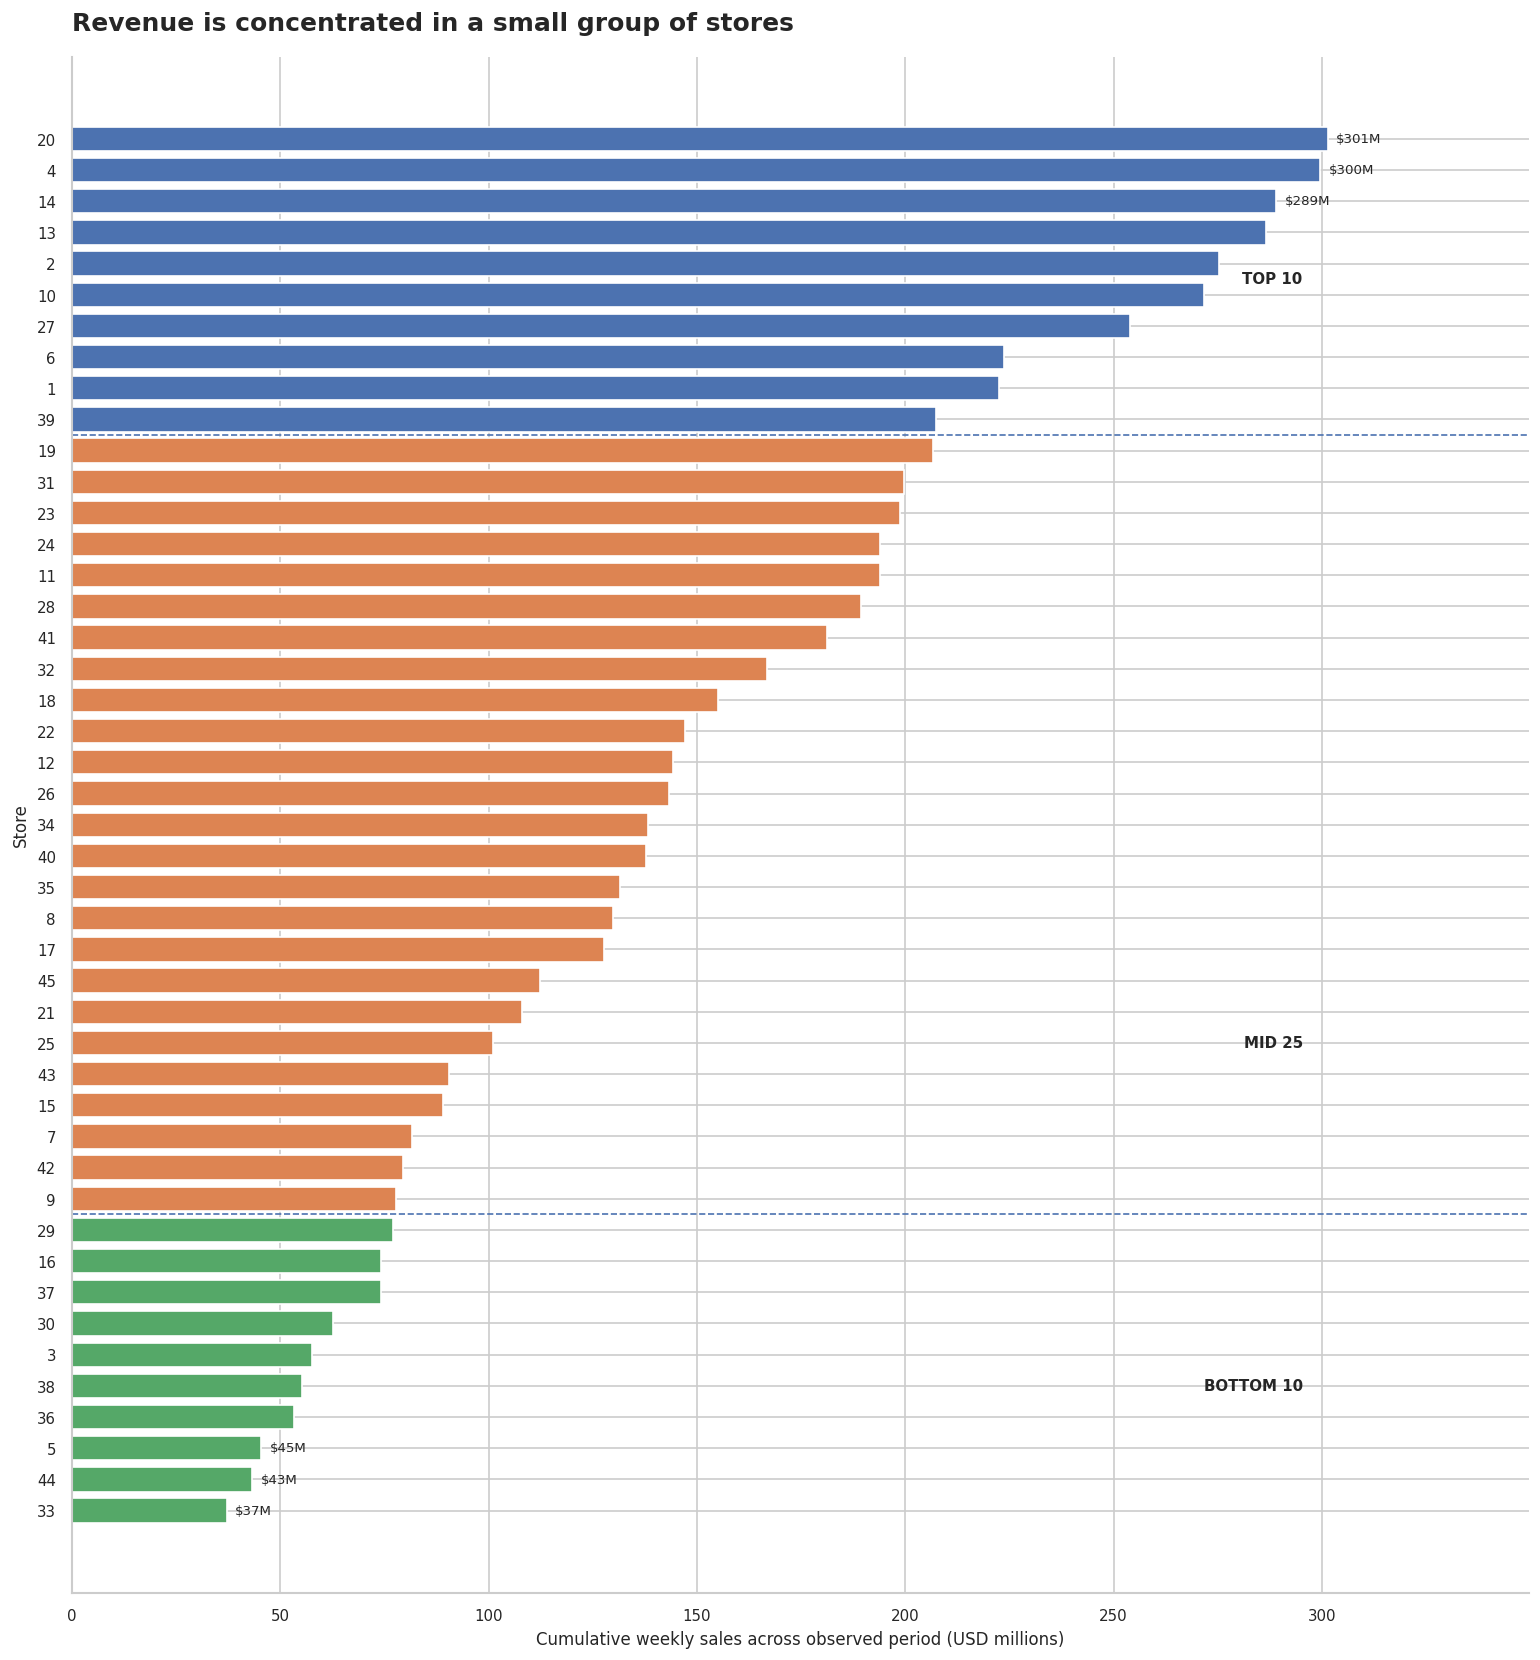

In [13]:

plot_store = store_performance.reset_index().sort_values("rank", ascending=True)
tier_colors = dict(zip(
    ["Top 10", "Mid 25", "Bottom 10"],
    sns.color_palette(n_colors=3)
))
bar_colors = plot_store["tier"].map(tier_colors)

fig, ax = plt.subplots(figsize=(13, 14))
ax.barh(
    plot_store["Store"].astype(str),
    plot_store["total_sales_m"],
    color=bar_colors,
    height=0.78
)
ax.invert_yaxis()
ax.set_title("Revenue is concentrated in a small group of stores", loc="left", pad=16)
ax.set_xlabel("Cumulative weekly sales across observed period (USD millions)")
ax.set_ylabel("Store")
ax.axhline(9.5, linestyle="--", linewidth=1)
ax.axhline(34.5, linestyle="--", linewidth=1)
ax.text(
    plot_store["total_sales_m"].max() * 0.98, 4.5,
    "TOP 10", ha="right", va="center", fontsize=9, fontweight="bold"
)
ax.text(
    plot_store["total_sales_m"].max() * 0.98, 29,
    "MID 25", ha="right", va="center", fontsize=9, fontweight="bold"
)
ax.text(
    plot_store["total_sales_m"].max() * 0.98, 40,
    "BOTTOM 10", ha="right", va="center", fontsize=9, fontweight="bold"
)
for _, row in plot_store.head(3).iterrows():
    ax.text(row["total_sales_m"] + 2, row.name, f"${row['total_sales_m']:.0f}M", va="center", fontsize=8)
for _, row in plot_store.tail(3).iterrows():
    ax.text(row["total_sales_m"] + 2, row.name, f"${row['total_sales_m']:.0f}M", va="center", fontsize=8)
ax.set_xlim(0, plot_store["total_sales_m"].max() * 1.16)
fig.tight_layout()
fig.savefig(VISUAL_DIR / "01_store_revenue_tiering.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)


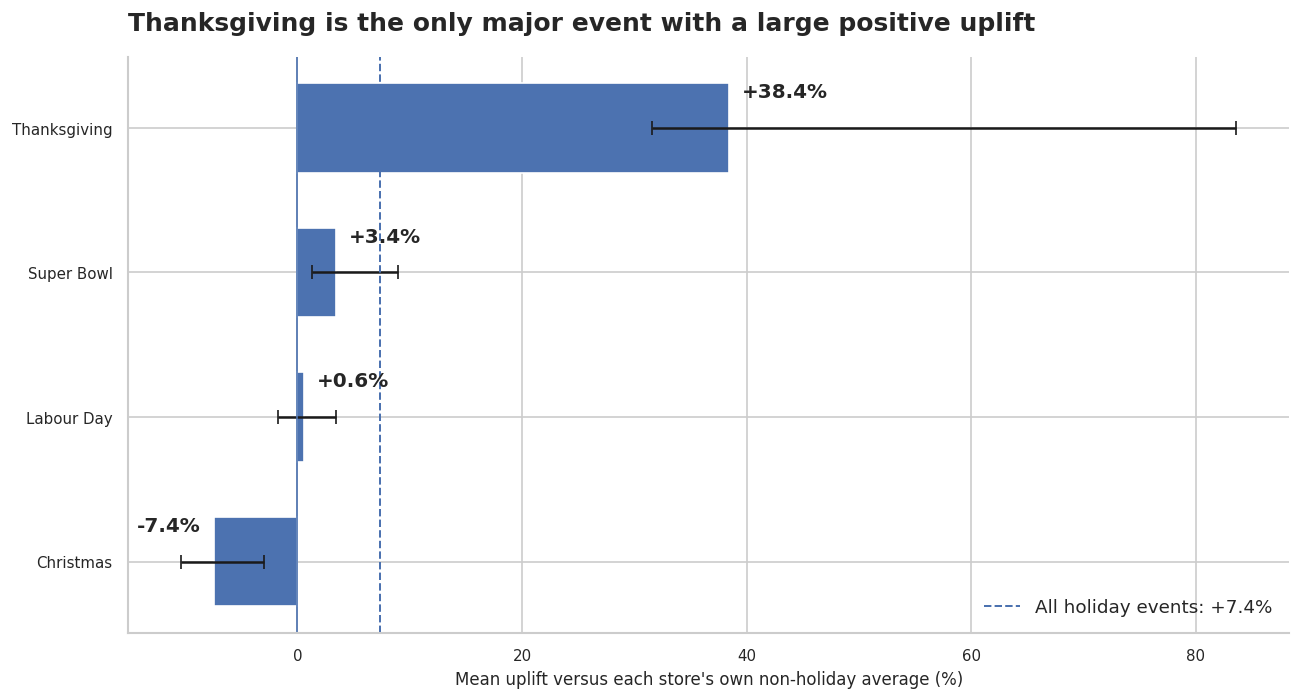

In [14]:

holiday_plot = holiday_uplift_summary.sort_values(
    "mean_store_adjusted_uplift_pct", ascending=True
).reset_index()

fig, ax = plt.subplots(figsize=(11, 6))
x = np.arange(len(holiday_plot))
means = holiday_plot["mean_store_adjusted_uplift_pct"].to_numpy()
lower = means - holiday_plot["ci_lower_pct"].to_numpy()
upper = holiday_plot["ci_upper_pct"].to_numpy()

ax.barh(
    holiday_plot["Holiday_Type"],
    means,
    xerr=np.vstack([np.abs(lower), np.abs(upper)]),
    capsize=4,
    height=0.62
)
ax.axvline(0, linewidth=1)
ax.axvline(
    overall_store_adjusted_uplift,
    linestyle="--",
    linewidth=1.2,
    label=f"All holiday events: {overall_store_adjusted_uplift:+.1f}%"
)
for y, value in enumerate(means):
    ax.text(
        value + (1.2 if value >= 0 else -1.2),
        y + 0.25,
        f"{value:+.1f}%",
        va="center",
        ha="left" if value >= 0 else "right",
        fontweight="bold"
    )
ax.set_title("Thanksgiving is the only major event with a large positive uplift", loc="left", pad=16)
ax.set_xlabel("Mean uplift versus each store's own non-holiday average (%)")
ax.set_ylabel("")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(VISUAL_DIR / "02_holiday_uplift.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)


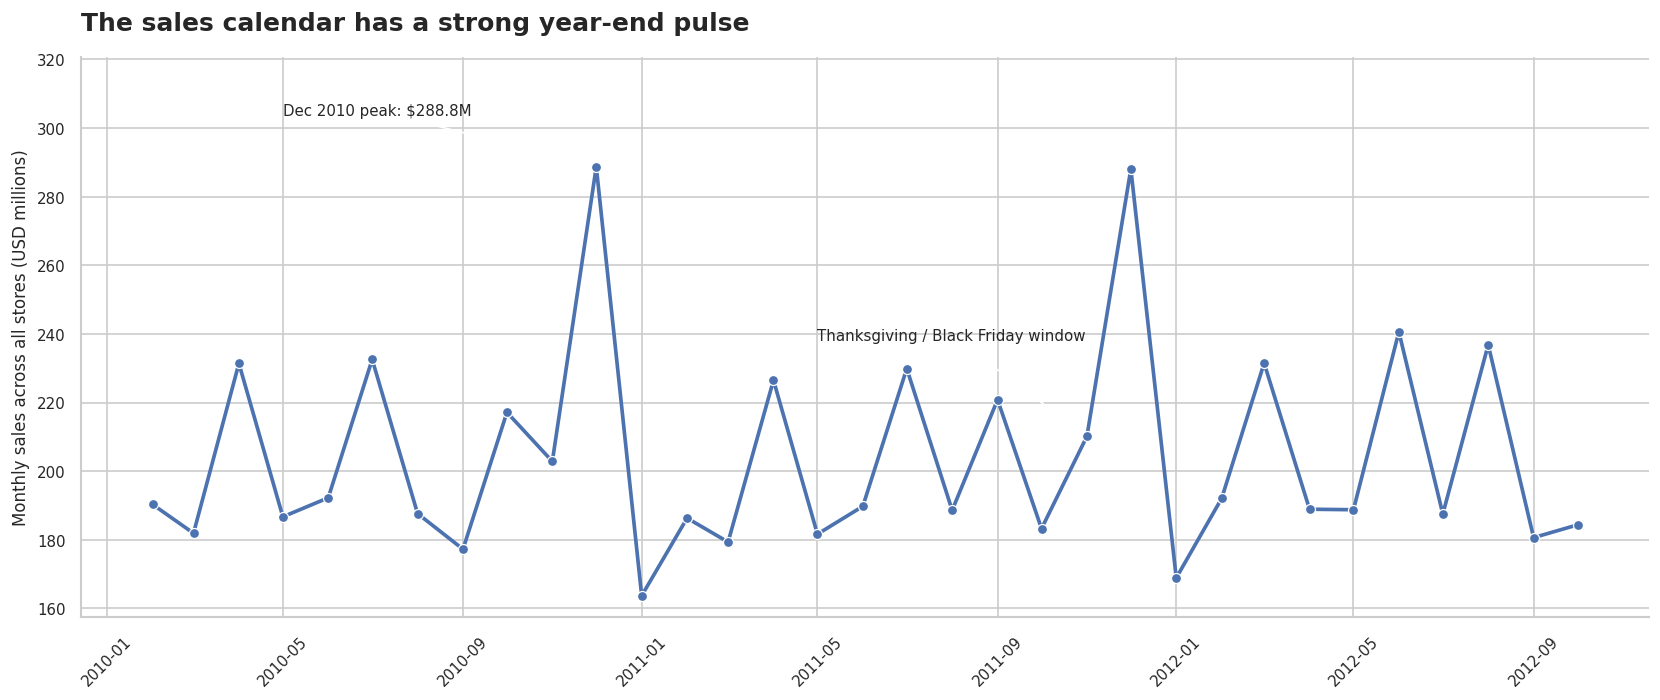

In [15]:

fig, ax = plt.subplots(figsize=(14, 6))
sns.lineplot(
    data=monthly_trend,
    x="Month_Start",
    y="monthly_sales_m",
    marker="o",
    linewidth=2.2,
    ax=ax
)
thanksgiving_month = pd.Timestamp("2011-11-01")
thanksgiving_value = monthly_trend.loc[
    monthly_trend["Month_Start"].eq(thanksgiving_month), "monthly_sales_m"
].iloc[0]
ax.annotate(
    "Thanksgiving / Black Friday window",
    xy=(thanksgiving_month, thanksgiving_value),
    xytext=(pd.Timestamp("2011-05-01"), thanksgiving_value + 28),
    arrowprops={"arrowstyle": "->", "linewidth": 1},
    fontsize=9
)
peak_x = peak_month["Month_Start"]
peak_y = peak_month["monthly_sales_m"]
ax.annotate(
    f"{peak_month['Month_Label']} peak: ${peak_y:.1f}M",
    xy=(peak_x, peak_y),
    xytext=(peak_x - pd.DateOffset(months=7), peak_y + 15),
    arrowprops={"arrowstyle": "->", "linewidth": 1},
    fontsize=9
)
ax.set_title("The sales calendar has a strong year-end pulse", loc="left", pad=16)
ax.set_ylim(top=monthly_trend["monthly_sales_m"].max() + 32)
ax.set_xlabel("")
ax.set_ylabel("Monthly sales across all stores (USD millions)")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(VISUAL_DIR / "03_monthly_sales_rhythm.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)


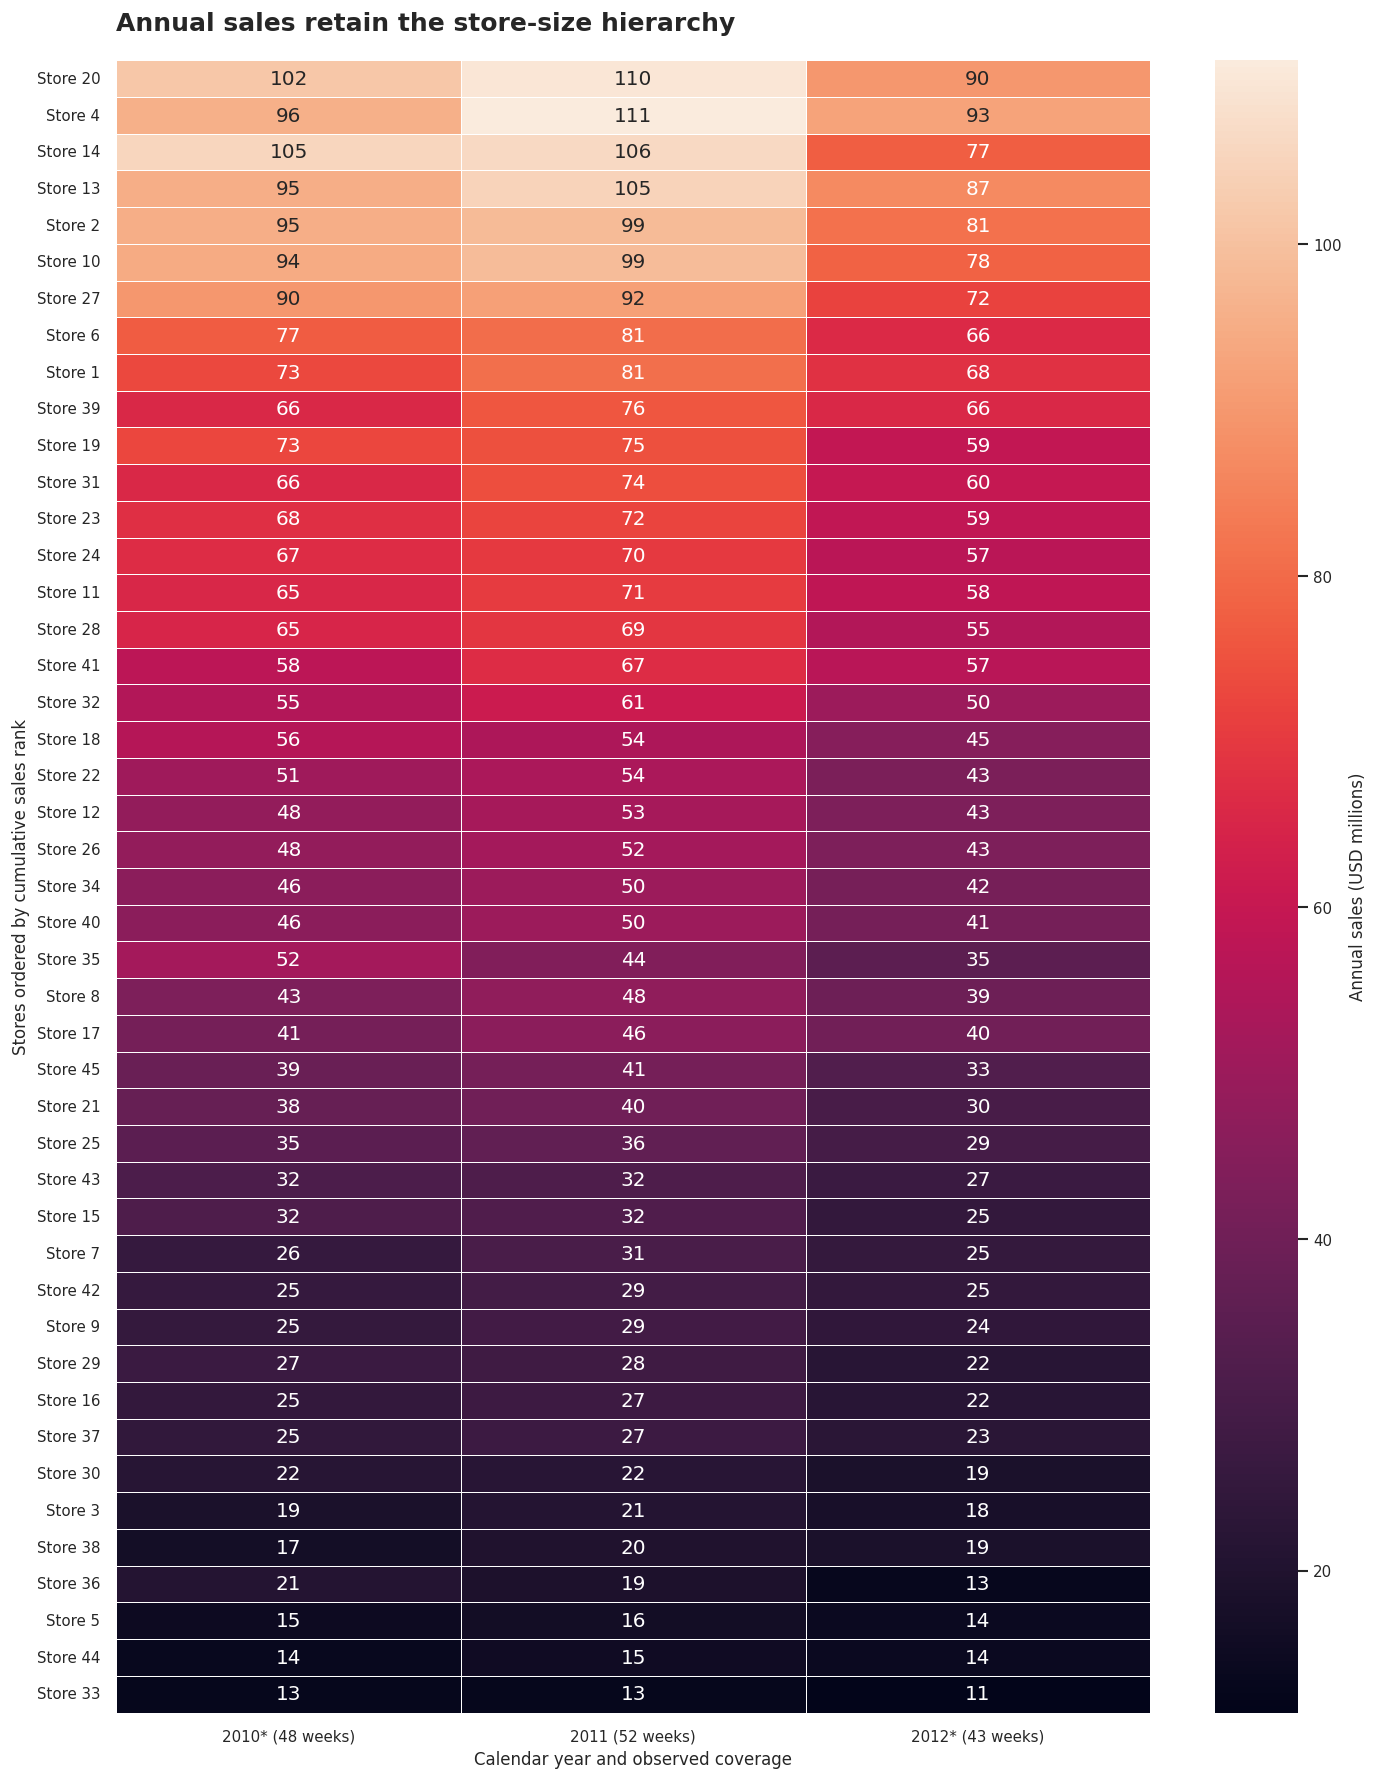

In [16]:

rank_order = store_performance.index.tolist()
heatmap_data = (store_year_pivot.loc[rank_order] / 1_000_000).copy()
heatmap_data.columns = ["2010* (48 weeks)", "2011 (52 weeks)", "2012* (43 weeks)"]
heatmap_data.index = [f"Store {store}" for store in heatmap_data.index]

fig, ax = plt.subplots(figsize=(12, 15))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    linewidths=0.35,
    linecolor="white",
    cbar_kws={"label": "Annual sales (USD millions)"},
    ax=ax
)
ax.set_title("Annual sales retain the store-size hierarchy", loc="left", pad=18)
ax.set_xlabel("Calendar year and observed coverage")
ax.set_ylabel("Stores ordered by cumulative sales rank")
fig.tight_layout()
fig.savefig(VISUAL_DIR / "04_store_year_sales_heatmap.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)


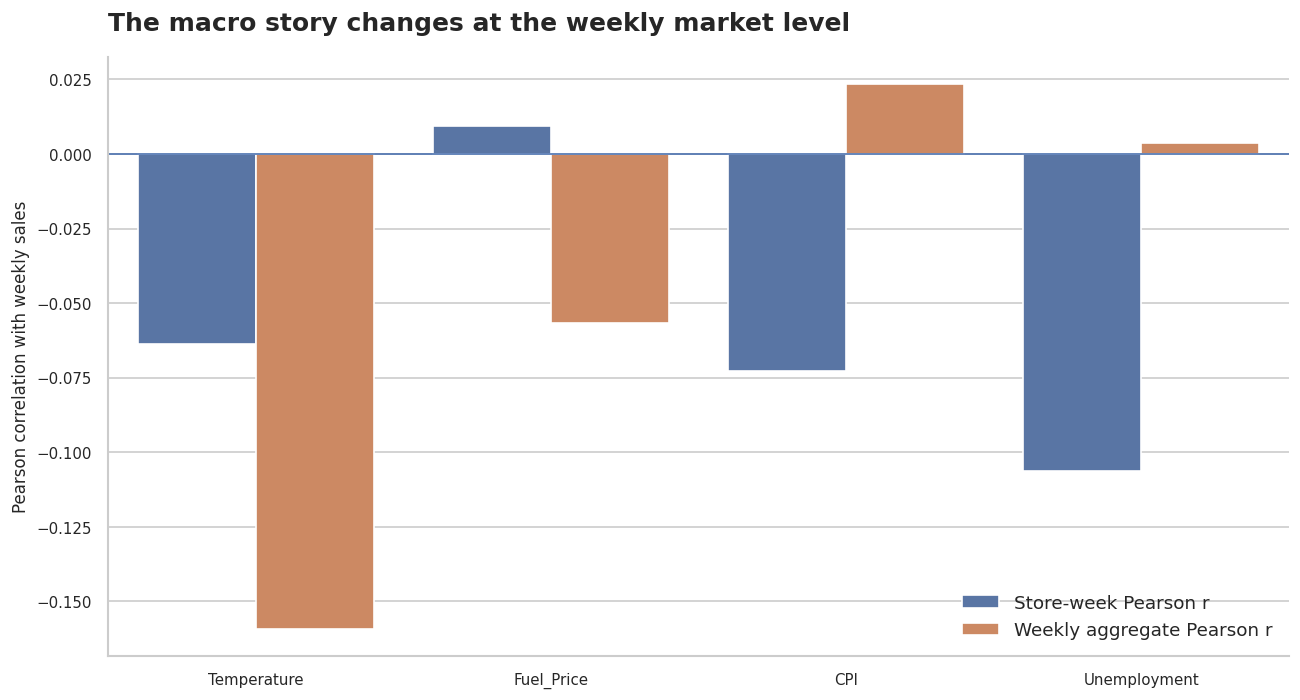

In [17]:

corr_long = macro_correlations.reset_index().melt(
    id_vars="Indicator",
    value_vars=["Store-week Pearson r", "Weekly aggregate Pearson r"],
    var_name="Observation unit",
    value_name="Pearson r"
)

fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(
    data=corr_long,
    x="Indicator",
    y="Pearson r",
    hue="Observation unit",
    ax=ax
)
ax.axhline(0, linewidth=1)
ax.set_title("The macro story changes at the weekly market level", loc="left", pad=16)
ax.set_xlabel("")
ax.set_ylabel("Pearson correlation with weekly sales")
ax.legend(title="")
fig.tight_layout()
fig.savefig(VISUAL_DIR / "05_macro_correlation_comparison.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)


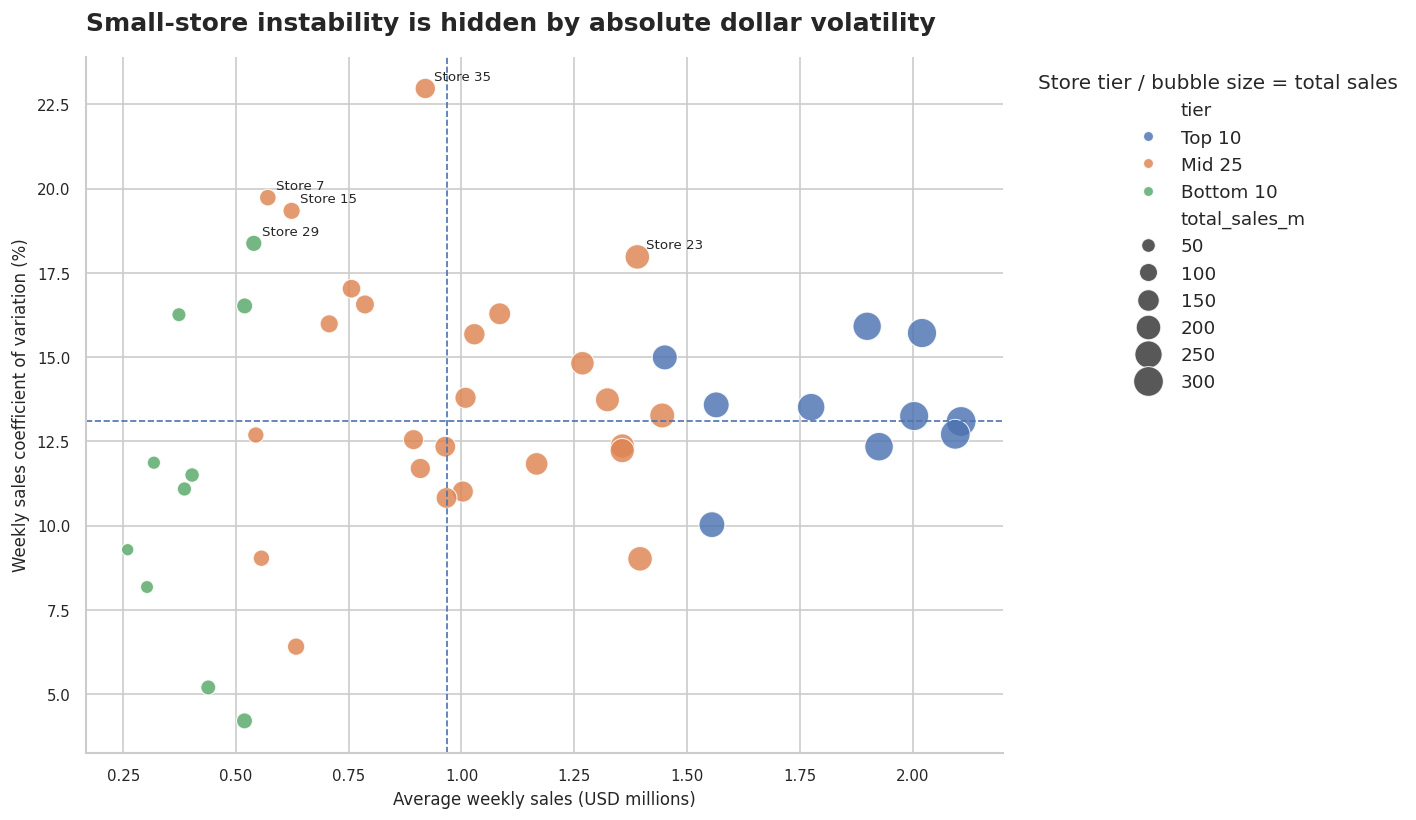

In [18]:

volatility_plot = store_performance.reset_index().copy()
volatility_plot["avg_weekly_sales_m"] = volatility_plot["avg_weekly_sales"] / 1_000_000
volatility_plot["total_sales_m"] = volatility_plot["total_sales"] / 1_000_000

fig, ax = plt.subplots(figsize=(12, 7))
sns.scatterplot(
    data=volatility_plot,
    x="avg_weekly_sales_m",
    y="cv_pct",
    hue="tier",
    size="total_sales_m",
    sizes=(55, 320),
    alpha=0.82,
    ax=ax
)
ax.axhline(volatility_plot["cv_pct"].median(), linestyle="--", linewidth=1)
ax.axvline(volatility_plot["avg_weekly_sales_m"].median(), linestyle="--", linewidth=1)
for store in store_performance.sort_values("cv_pct", ascending=False).head(5).index:
    row = volatility_plot.loc[volatility_plot["Store"].eq(store)].iloc[0]
    ax.annotate(
        f"Store {store}",
        (row["avg_weekly_sales_m"], row["cv_pct"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )
ax.set_title("Small-store instability is hidden by absolute dollar volatility", loc="left", pad=16)
ax.set_xlabel("Average weekly sales (USD millions)")
ax.set_ylabel("Weekly sales coefficient of variation (%)")
ax.legend(title="Store tier / bubble size = total sales", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(VISUAL_DIR / "06_store_volatility_map.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)


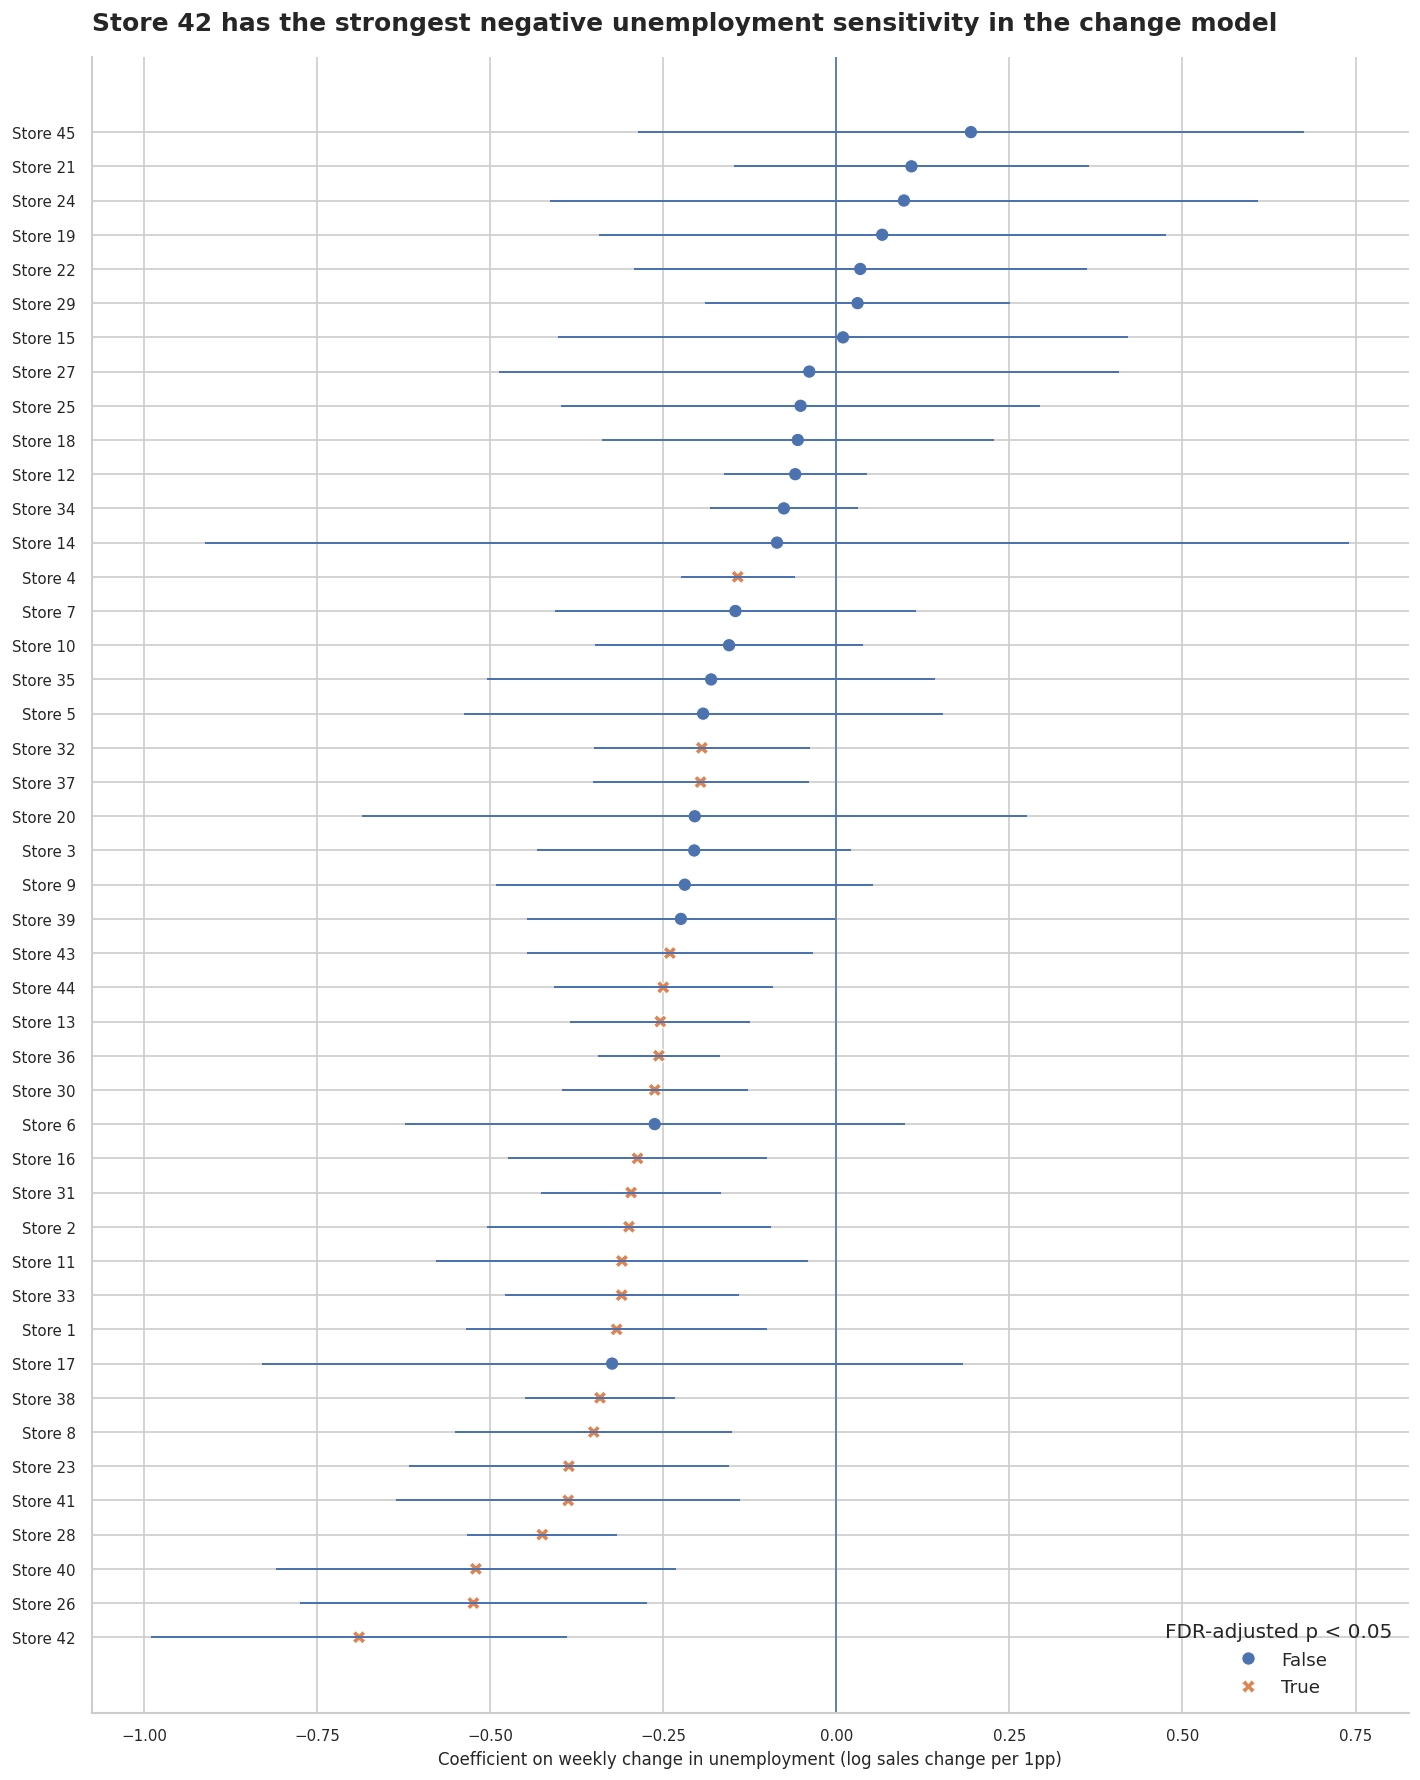

In [19]:

sensitivity_plot = unemployment_sensitivity.reset_index().sort_values(
    "beta_unemployment_change", ascending=True
).copy()

fig, ax = plt.subplots(figsize=(12, 15))
y_positions = np.arange(len(sensitivity_plot))
ax.hlines(
    y=y_positions,
    xmin=sensitivity_plot["ci_lower"],
    xmax=sensitivity_plot["ci_upper"],
    linewidth=1.2
)
sns.scatterplot(
    data=sensitivity_plot,
    x="beta_unemployment_change",
    y=y_positions,
    hue="fdr_significant",
    style="fdr_significant",
    s=65,
    ax=ax
)
ax.axvline(0, linewidth=1)
ax.set_yticks(y_positions)
ax.set_yticklabels([f"Store {s}" for s in sensitivity_plot["Store"]])
ax.set_title("Store 42 has the strongest negative unemployment sensitivity in the change model", loc="left", pad=16)
ax.set_xlabel("Coefficient on weekly change in unemployment (log sales change per 1pp)")
ax.set_ylabel("")
ax.legend(title="FDR-adjusted p < 0.05", loc="lower right")
fig.tight_layout()
fig.savefig(VISUAL_DIR / "07_unemployment_sensitivity_forest.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)



## Regional manager readout

The final queue combines portfolio economics with calendar and risk signals. These are operational prompts for investigation, not causal claims about store management or local demand.


In [20]:

top10_share = tier_summary.loc["Top 10", "sales_share_pct"]
bottom10_share = tier_summary.loc["Bottom 10", "sales_share_pct"]
highest_cv_store = int(store_performance["cv_pct"].idxmax())
highest_std_store = int(store_performance["std_weekly_sales"].idxmax())
store42_delta = unemployment_sensitivity.loc[42, "beta_unemployment_change"]
store42_level = level_sensitivity.loc[42, "level_beta_unemployment"]

manager_insights = [
    (
        f"Protect the Thanksgiving operating window. Store-normalized uplift is "
        f"{holiday_uplift_summary.loc['Thanksgiving', 'mean_store_adjusted_uplift_pct']:+.1f}%, "
        f"while Christmas is {holiday_uplift_summary.loc['Christmas', 'mean_store_adjusted_uplift_pct']:+.1f}%. "
        "Treat the two events as different inventory and staffing profiles."
    ),
    (
        f"Use the Top 10 as the network's revenue anchor: they contribute "
        f"{top10_share:.1f}% of sales, while the Bottom 10 contribute "
        f"{bottom10_share:.1f}%. Benchmark practices by tier, but do not assume "
        "the same sales opportunity in every location."
    ),
    (
        f"Investigate relative instability at Store {highest_cv_store}, the highest "
        f"CV store at {store_performance.loc[highest_cv_store, 'cv_pct']:.1f}%. "
        f"Store {highest_std_store} has the largest dollar standard deviation, "
        "but that partly reflects its larger sales base."
    ),
    (
        f"Open a recovery review for {len(investigation_queue)} stores that declined "
        "on the 2012-vs-2011 February–October like-for-like comparison despite "
        "positive 2012 holiday-week uplift. Store 36 is the sharpest decline."
    ),
    (
        f"Treat Store 42 as the first unemployment-exposure review: it ranks most "
        f"negative in both the weekly-change model ({store42_delta:+.3f}) and the "
        f"level robustness model ({store42_level:+.3f}). Validate this signal with "
        "local customer, category and competitor information before changing plans."
    ),
]

for index, insight in enumerate(manager_insights, start=1):
    print(f"{index}. {insight}")


1. Protect the Thanksgiving operating window. Store-normalized uplift is +38.4%, while Christmas is -7.4%. Treat the two events as different inventory and staffing profiles.
2. Use the Top 10 as the network's revenue anchor: they contribute 39.1% of sales, while the Bottom 10 contribute 8.6%. Benchmark practices by tier, but do not assume the same sales opportunity in every location.
3. Investigate relative instability at Store 35, the highest CV store at 23.0%. Store 14 has the largest dollar standard deviation, but that partly reflects its larger sales base.
4. Open a recovery review for 7 stores that declined on the 2012-vs-2011 February–October like-for-like comparison despite positive 2012 holiday-week uplift. Store 36 is the sharpest decline.
5. Treat Store 42 as the first unemployment-exposure review: it ranks most negative in both the weekly-change model (-0.689) and the level robustness model (-0.707). Validate this signal with local customer, category and competitor informati


## Export the analysis tables

The exported tables make the results reusable outside the notebook: in a BI tool, a presentation or a follow-up store review. The source CSV remains unchanged.


In [21]:

store_performance.to_csv(OUTPUT_DIR / "store_performance_and_tiers.csv")
tier_summary.to_csv(OUTPUT_DIR / "store_tier_contribution.csv")
holiday_uplift_summary.to_csv(OUTPUT_DIR / "holiday_uplift_by_type.csv")
holiday_date_sales.to_csv(OUTPUT_DIR / "holiday_date_sales.csv", index=False)
monthly_trend.to_csv(OUTPUT_DIR / "monthly_sales_trend.csv", index=False)
store_year_pivot.to_csv(OUTPUT_DIR / "store_year_sales_pivot.csv")
store_year_yoy.to_csv(OUTPUT_DIR / "store_year_yoy_growth_pct.csv")
like_for_like_growth.to_csv(OUTPUT_DIR / "store_like_for_like_growth_pct.csv")
highest_relative_volatility.to_csv(OUTPUT_DIR / "store_volatility_ranking.csv")
macro_correlations.to_csv(OUTPUT_DIR / "macro_correlation_comparison.csv")
unemployment_sensitivity.to_csv(OUTPUT_DIR / "store_unemployment_sensitivity.csv")
sensitivity_robustness.to_csv(OUTPUT_DIR / "unemployment_model_robustness.csv")
investigation_queue.to_csv(OUTPUT_DIR / "stores_for_investigation.csv")

print("Exported 13 analysis tables.")
print("Saved 7 visualizations in the visuals/ folder.")


Exported 13 analysis tables.
Saved 7 visualizations in the visuals/ folder.



## Interpretation boundaries

- Weekly sales are observed revenue values in the source; the file does not include units, margin, inventory, promotions, local competition or store operating hours.
- `Holiday_Flag` marks a holiday-associated week. It does not isolate the causal effect of a single promotion or shopping day.
- The holiday event sample contains two Thanksgiving dates and two Christmas dates, because the file ends before the 2012 dates for those events.
- The 2010 and 2012 annual totals are partial. Use the February–October 39-week comparison for like-for-like store growth.
- Macro indicators vary by store and week, while all stores share the same weekly calendar. The market-level correlation uses 143 weekly aggregates and should be read alongside the pooled store-week result.
- CPI, fuel price, unemployment and time are strongly related in this historical sample. Store-specific regression coefficients are descriptive exposure signals, not causal elasticities.
- Unemployment changes in only a small number of weekly transitions. The sensitivity ranking should guide investigation, not be used as a stand-alone forecast.
